## <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 6</span>


In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 06.1

## Results ##

#### 1D Ising Model: Metropolis vs. Gibbs Sampling

The objective of this exercise is to simulate a 1D Ising model and compute the mean values of key thermodynamic observables:
* **Internal Energy:** $U(N,T) = \langle H \rangle_{h=0}$
* **Heat Capacity:** $C(N,T) = k_B \beta^2 \left( \langle H^2 \rangle_{h=0} - \langle H \rangle_{h=0}^2 \right)$
* **Magnetic Susceptibility:** $\chi(N,T) = \beta \langle \left( \sum_{i=1}^N s_i \right)^2 \rangle_{h=0}$
* **Magnetization:** $M(N,T,h=0.02) = \langle \sum_{i=1}^N s_i \rangle_{h=0.02}$

These estimates were obtained by comparing two distinct Monte Carlo approaches: standard sampling via the Metropolis algorithm and conditional sampling via the Gibbs algorithm.



#### Gibbs Sampling Theory & Implementation Details

Gibbs sampling is a Markov Chain Monte Carlo (MCMC) technique used to generate configurations distributed according to the Boltzmann distribution:
$$p(\{ s_i \}) = \frac{e^{-\beta H}}{Z}$$

where $\{ s_i \}$ is a particular configuration of spins with $s_i = \pm 1$, and $H$ is the Hamiltonian of the system. For the 1D Ising Model (with $N$ spins), it is defined as:
$$H = -J \sum_{i=1}^N s_i s_{i+1} - h \sum_{i=1}^N s_i$$

where $h$ is the external magnetic field and $J$ is the coupling constant ($J > 0$ denotes the ferromagnetic case, while $J < 0$ corresponds to the anti-ferromagnetic case).

#### Metropolis vs. Gibbs
* In the Metropolis algorithm, a trial move is proposed and subsequently accepted or rejected based on an acceptance probability.
* In Gibbs sampling, we directly sample a single spin from its conditional probability, update that spin while keeping all others fixed, and repeat the process.

For a given spin $s_i$, the conditional probability depends on the local effective field $b_i$ produced by its nearest neighbors and the external field:
$$b_i = J(s_{i-1} + s_{i+1}) + h$$

The conditional probability of finding spin $s_i$ in state $+1$ given the rest of the system is:
$$P(s_i = +1 \mid \text{rest}) = \frac{1}{1 + e^{-2\beta b_i}}$$

#### Monte Carlo Step Structure
For each Monte Carlo step (sweeping through the system):
1. **Random Selection:** Select a spin index $i$ randomly. Note that this selection must be random; choosing spins sequentially in a fixed order would introduce a systematic bias into the simulation.
2. **Local Field:** Compute the local effective field $b_i$ from its neighbors. Special care must be taken when evaluating neighbors to properly enforce **periodic boundary conditions (PBC)** to simulate an infinite system.
3. **Probability Evaluation:** Compute the conditional probability $P = \frac{1}{1 + e^{-2\beta b_i}}$.
4. **Random Draw:** Draw a uniform random number $r \in [0, 1)$.
5. **Spin Update:** Update the spin state: set $s_i = +1$ if $r < P$, else set $s_i = -1$.




#### Equilibrating and Performance Observations

1. **Equilibration Phase:**
   As seen in Exercise 5, both sampling methods require a preliminary equilibration phase to relax the initial configuration into a state compatible with the target Boltzmann distribution.

2. **Agreement with Theory:**
   The numerical results from both Metropolis and Gibbs sampling demonstrate excellent convergence and match the analytical predictions of the 1D Ising model very closely.

3. **Behavior of Statistical Errors at Low Temperatures:**
   We can notice that the statistical uncertainties (error bars) increase at lower temperatures. This occurs because at lower temperatures ($\beta = 1/k_B T$ is large), both Metropolis and Gibbs algorithms trigger fewer effective changes in the spin values. Consequently, the system exhibits higher autocorrelation and variance, requiring longer simulation runs to achieve the same precision.



### Simulation Parameters

* **Number of Blocks (`NBLOCKS`):** 100
* **Steps per Block (`NSTEPS`):** 6000
* **Equilibration Steps (`n_equil`):** 
  * $9000$ if $T > 0.9$
  * $500000$ if $T \le 0.9$

```cpp
// Equilibration loop
int n_equil = (T > 0.9) ? 9000 : 500000; 
for(int e = 0; e < n_equil; e++) SYS.step();
---

 **Exercise**
 
Complete the NSL_simulator code to simulate a 1D Ising model with the Gibbs sampling algorithm (the Metropolis algorithm is already implemented) to sample the Boltzmann's weight $p(\{ s_i \}) = \exp(-\beta H)/Z$. Verify the possibility to restart from a previous spin configuration.

The code already computes the internal energy: $U(N,T) = \langle H \rangle$. Add the calculation of $C(N,T)$, $\chi(N,T)$, $M(N,T,h)$ and compute:
1. $U(N,T) = \langle H \rangle_{h=0}$
2. $C(N,T) = k_B \beta^2 (\langle H^2 \rangle_{h=0}-\langle H \rangle_{h=0}^2)$ 
3. $\chi(N,T) = \beta \langle (\sum_{i=1,N}s_i)^2 \rangle_{h=0}$
4. $M(N,T,h=0.02)= \langle \sum_{i=1,N}s_i \rangle_{h=0.02}$

as a function of $T$ in the range $\left[0.5;2.0\right]$ for a system of $N=50$ spins with $J=1$.

As usual, use data blocking and give an estimate of the statistical uncertainties.

- <span style="color:red">Show pictures of your estimations of $U(N,T)$, $C(N,T)$, $\chi(N,T)$, $M(N,T,h=0.02)$ and their uncertainties</span> obtained with a large number of *MC steps* (e.g. $M\ge 10^5$) compared with the exact curves. In the same picture show your results obtained with <span style="color:blue">both sampling methods, Metropolis and Gibbs</span>.

A Monte Carlo step will consist in trying to flip one time all the spins of the system. Do not forget to equilibrate your simulations and to use blocking average with blocks large enough.


# Metropolis Algorithm

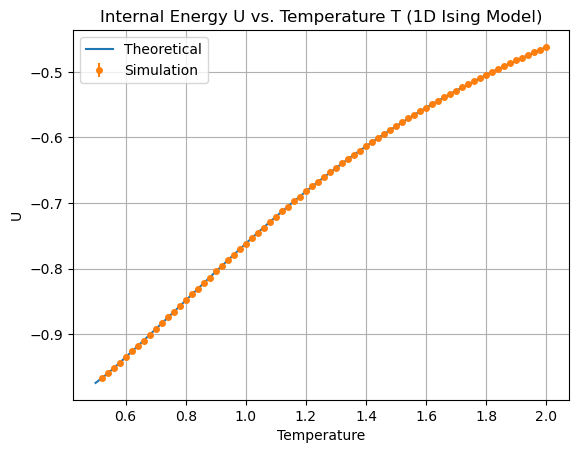

In [9]:
data_mu = np.loadtxt("total_energy.dat")
x_mu = data_mu[:, 0]
mean_mu = data_mu[:, 2]
err_mu = data_mu[:, 3]

# fit con curva blu 
points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1 / th
e = -J * (th + ch * thN) / (1 + thN)

plt.plot(T, e, label="Theoretical")
plt.errorbar(x_mu, mean_mu, yerr=err_mu, fmt="o", ms=4, label="Simulation")

plt.xlabel("Temperature")
plt.ylabel("U")
plt.title("Internal Energy U vs. Temperature T (1D Ising Model)")
plt.legend()
plt.grid(True)

plt.show()

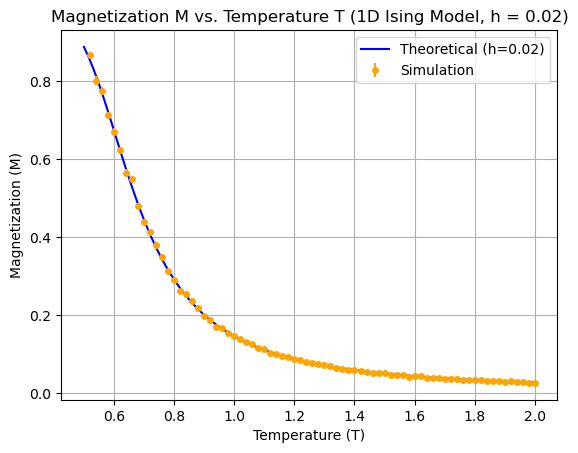

In [11]:
data_mm = np.loadtxt("magnetization.dat")
x_mm = data_mm[:, 0]
mean_mm = data_mm[:, 2]
err_mm = data_mm[:, 3]

# Theoretical curve for 1D Ising Magnetization with external field h
points = 100
T = np.linspace(0.5, 2.0, num=points)
b = 1 / T
J = 1.0
Ns = 50
h = 0.02  # External magnetic field

# Transfer matrix eigenvalues for Ising model with field h
term = np.sqrt(
    np.exp(2 * b * J) * np.cosh(b * h) * np.cosh(b * h) - 2 * np.sinh(2 * b * J)
)
l1 = np.exp(b * J) * np.cosh(b * h) + term
l2 = np.exp(b * J) * np.cosh(b * h) - term
Z = l1**Ns + l2**Ns

# Magnetization derivative formula
M = (
    np.exp(b * J)
    * np.sinh(b * h)
    * (
        (l1 ** (Ns - 1)) * (1 + np.exp(b * J) * np.cosh(b * h) / term)
        + (l2 ** (Ns - 1)) * (1 - np.exp(b * J) * np.cosh(b * h) / term)
    )
) / Z

plt.plot(T, M, label="Theoretical (h=0.02)", color="blue")
plt.errorbar(
    x_mm, mean_mm, yerr=err_mm, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel("Temperature (T)")
plt.ylabel("Magnetization (M)")
plt.title("Magnetization M vs. Temperature T (1D Ising Model, h = 0.02)")
plt.legend()
plt.grid(True)

plt.show()

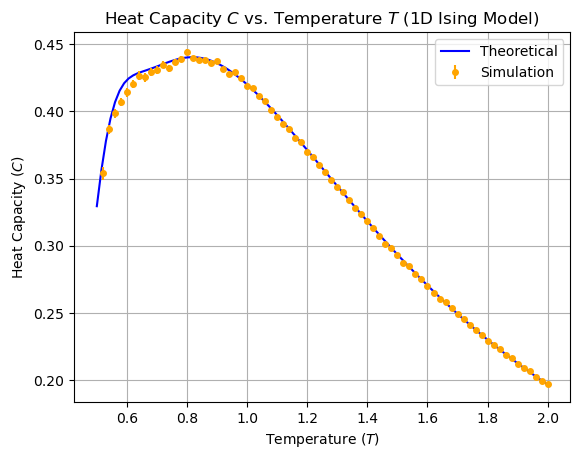

In [6]:
data_mc = np.loadtxt("specific_heat.dat")
x_mc = data_mc[:, 0]     
mean_mc = data_mc[:, 1]  
err_mc = data_mc[:, 2]


points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1.0 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1.0 / th


heat = ((beta * J) ** 2) * (
    ((1 + thN + (Ns - 1) * (th**2) + (Ns - 1) * (ch**2) * thN) / (1 + thN))
    - Ns * ((th + ch * thN) / (1 + thN)) ** 2
)

# Plotting
plt.plot(T, heat, label="Theoretical", color="blue")
plt.errorbar(
    x_mc, mean_mc, yerr=err_mc, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"Heat Capacity ($C$)")
plt.title(r"Heat Capacity $C$ vs. Temperature $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)

plt.show()

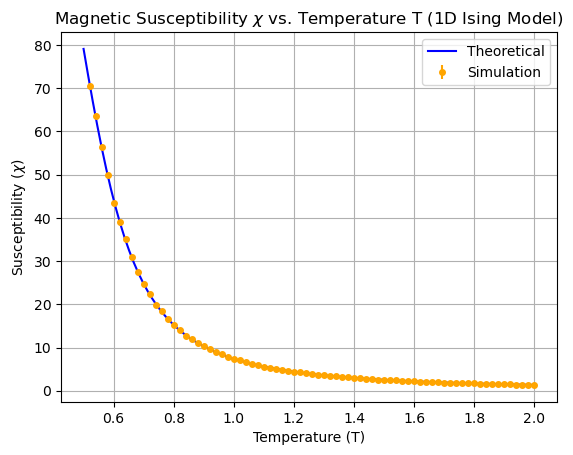

In [15]:


data_mchi = np.loadtxt("susceptibility.dat")
x_mchi = data_mchi[:, 0]
mean_mchi = data_mchi[:, 2]
err_mchi = data_mchi[:, 3]

# Theoretical curve for 1D Ising Susceptibility (h = 0)
points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns

X = beta * np.exp(2 * beta * J) * (1 - thN) / (1 + thN)

plt.plot(T, X, label="Theoretical", color="blue")
plt.errorbar(
    x_mchi, mean_mchi, yerr=err_mchi, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel("Temperature (T)")
plt.ylabel(r"Susceptibility ($\chi$)")
plt.title(
    r"Magnetic Susceptibility $\chi$ vs. Temperature T (1D Ising Model)"
)  
plt.legend()
plt.grid(True)

plt.show()

## Gibbs Algorithm

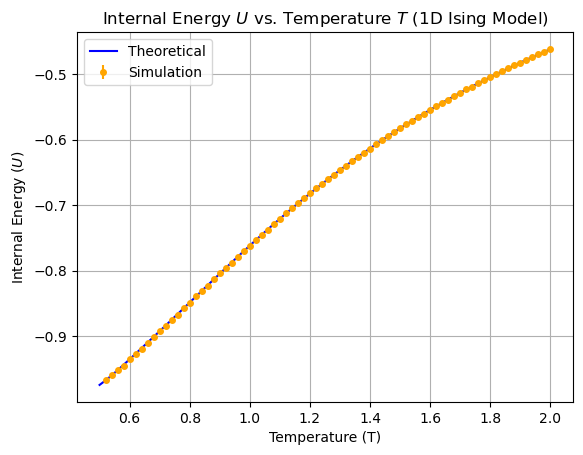

In [17]:
data_gu = np.loadtxt("total_energy2.dat")
x_gu = data_gu[:, 0]  
mean_gu = data_gu[:, 2]  
err_gu = data_gu[:, 3]  


points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1 / th
e = -J * (th + ch * thN) / (1 + thN)

# Plotting
plt.plot(T, e, label="Theoretical", color="blue")
plt.errorbar(
    x_gu, mean_gu, yerr=err_gu, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel("Temperature (T)")
plt.ylabel(r"Internal Energy ($U$)")
plt.title(r"Internal Energy $U$ vs. Temperature $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)

plt.show()


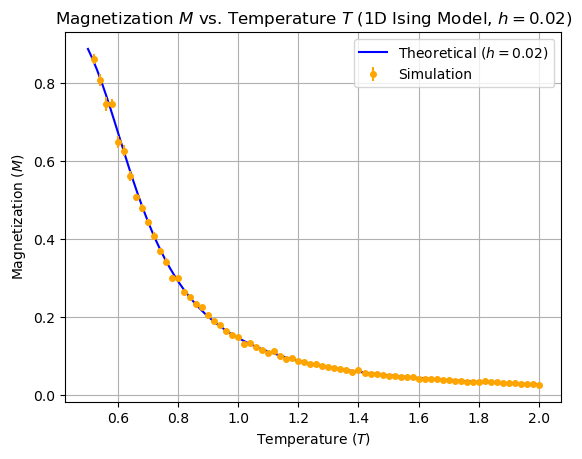

In [19]:

data_gm = np.loadtxt("magnetization2.dat")
x_gm = data_gm[:, 0]     
mean_gm = data_gm[:, 2]  
err_gm = data_gm[:, 3]   

points = 100
T = np.linspace(0.5, 2.0, num=points)
b = 1.0 / T
J = 1.0
Ns = 50
h = 0.02  # External magnetic field

term = np.sqrt(
    np.exp(2 * b * J) * np.cosh(b * h) * np.cosh(b * h) - 2 * np.sinh(2 * b * J)
)
l1 = np.exp(b * J) * np.cosh(b * h) + term
l2 = np.exp(b * J) * np.cosh(b * h) - term
Z = l1**Ns + l2**Ns

M = (
    np.exp(b * J)
    * np.sinh(b * h)
    * (
        (l1 ** (Ns - 1)) * (1 + np.exp(b * J) * np.cosh(b * h) / term)
        + (l2 ** (Ns - 1)) * (1 - np.exp(b * J) * np.cosh(b * h) / term)
    )
) / Z

# Plotting
plt.plot(T, M, label=r"Theoretical ($h=0.02$)", color="blue")
plt.errorbar(
    x_gm, mean_gm, yerr=err_gm, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"Magnetization ($M$)")
plt.title(r"Magnetization $M$ vs. Temperature $T$ (1D Ising Model, $h=0.02$)")
plt.legend()
plt.grid(True)

plt.show()

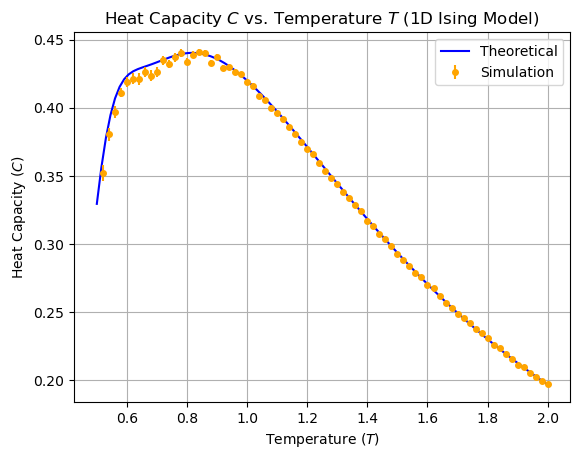

In [8]:
data_gc = np.loadtxt("specific_heat2.dat")
x_gc = data_gc[:, 0]     
mean_gc = data_gc[:, 1]  
err_gc = data_gc[:, 2]   


points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1.0 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1.0 / th


heat = ((beta * J) ** 2) * (
    ((1 + thN + (Ns - 1) * (th**2) + (Ns - 1) * (ch**2) * thN) / (1 + thN))
    - Ns * ((th + ch * thN) / (1 + thN)) ** 2
)

# Plotting
plt.plot(T, heat, label="Theoretical", color="blue")
plt.errorbar(
    x_gc, mean_gc, yerr=err_gc, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"Heat Capacity ($C$)")
plt.title(r"Heat Capacity $C$ vs. Temperature $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)

plt.show()

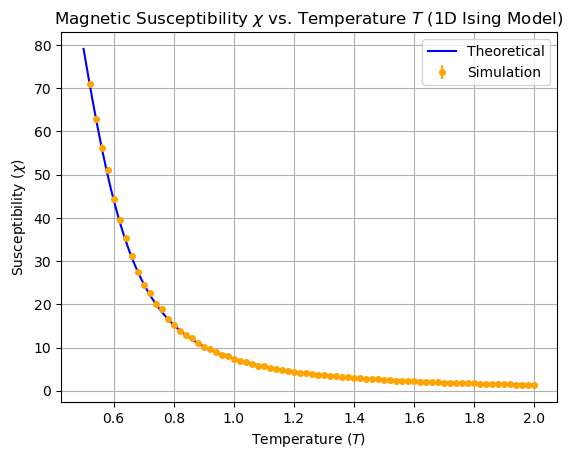

In [25]:
data_gchi = np.loadtxt("susceptibility2.dat")
x_gchi = data_gchi[:, 0]     
mean_gchi = data_gchi[:, 2]  
err_gchi = data_gchi[:, 3]  


points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1.0 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns

X = beta * np.exp(2 * beta * J) * (1 - thN) / (1 + thN)

# Plotting
plt.plot(T, X, label="Theoretical", color="blue")
plt.errorbar(
    x_gchi, mean_gchi, yerr=err_gchi, fmt="o", ms=4, label="Simulation", color="orange"
)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"Susceptibility ($\chi$)")
plt.title(
    r"Magnetic Susceptibility $\chi$ vs. Temperature $T$ (1D Ising Model)"
)
plt.legend()
plt.grid(True)

plt.show()

# Gibbs vs. Metropolis

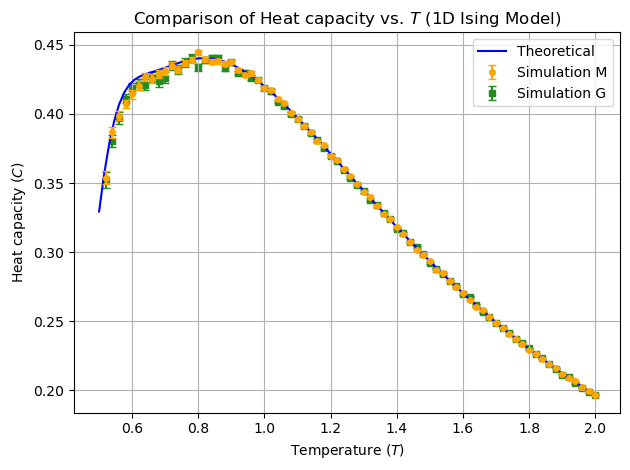

In [10]:
points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1.0 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1.0 / th


heat = ((beta * J) ** 2) * (
    ((1 + thN + (Ns - 1) * (th**2) + (Ns - 1) * (ch**2) * thN) / (1 + thN))
    - Ns * ((th + ch * thN) / (1 + thN)) ** 2
)

# Plotting
plt.plot(T, heat, label="Theoretical", color="blue")

# First simulation
plt.errorbar(
    x_mc,
    mean_mc,
    yerr=err_mc,
    fmt="o",
    ms=4,
    label="Simulation M",
    color="orange",
    capsize=3,
    zorder=2,
)

# Second simulation
plt.errorbar(
    x_gc,
    mean_gc,
    yerr=err_gc,
    fmt="s",
    ms=4,
    label="Simulation G",
    color="forestgreen",
    capsize=3,
    zorder=1,
)

plt.xlabel("Temperature ($T$)")
plt.ylabel(r"Heat capacity ($C$)")
plt.title(r"Comparison of Heat capacity vs. $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

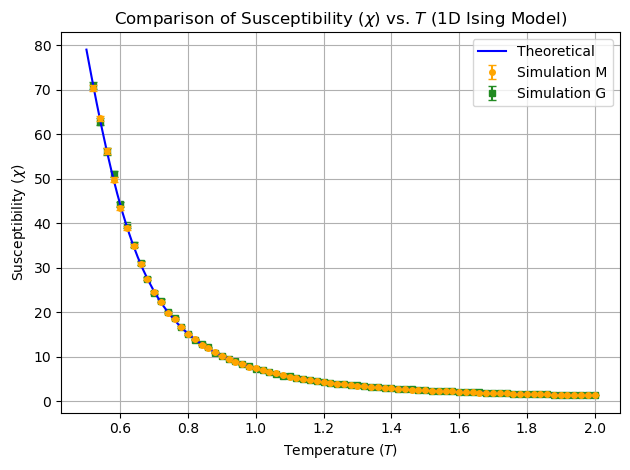

In [58]:
points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1.0 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns

X = beta * np.exp(2 * beta * J) * (1 - thN) / (1 + thN)

# Plotting
plt.plot(T, X, label="Theoretical", color="blue")

# First simulation
plt.errorbar(
    x_mchi,
    mean_mchi,
    yerr=err_mchi,
    fmt="o",
    ms=4,
    label="Simulation M",
    color="orange",
    capsize=3,
    zorder=2,
)

# Second simulation
plt.errorbar(
    x_gchi,
    mean_gchi,
    yerr=err_gchi,
    fmt="s",
    ms=4,
    label="Simulation G",
    color="forestgreen",
    capsize=3,
    zorder=1,
)

plt.xlabel("Temperature ($T$)")
plt.ylabel(r"Susceptibility ($\chi$)")
plt.title(r"Comparison of Susceptibility ($\chi$) vs. $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

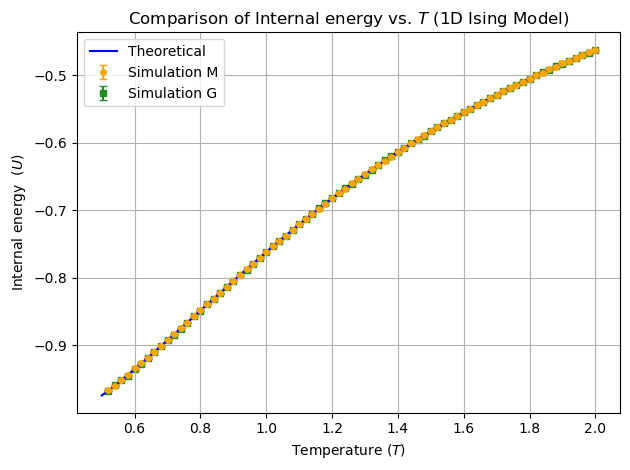

In [56]:
points = 100
T = np.linspace(0.5, 2.0, num=points)
beta = 1 / T
J = 1.0
Ns = 50
th = np.tanh(J / T)
thN = th**Ns
ch = 1 / th
e = -J * (th + ch * thN) / (1 + thN)

# Plotting
plt.plot(T, e, label="Theoretical", color="blue")



# First simulation
plt.errorbar(
    x_mu,
    mean_mu,
    yerr=err_mu,
    fmt="o",
    ms=4,
    label="Simulation M",
    color="orange",
    capsize=3,
    zorder=2,
)

# Second simulation
plt.errorbar(
    x_gu,
    mean_gu,
    yerr=err_gu,
    fmt="s",
    ms=4,
    label="Simulation G",
    color="forestgreen",
    capsize=3,
    zorder=1,
)

plt.xlabel("Temperature ($T$)")
plt.ylabel(r"Internal energy  ($U$)")
plt.title(r"Comparison of Internal energy vs. $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

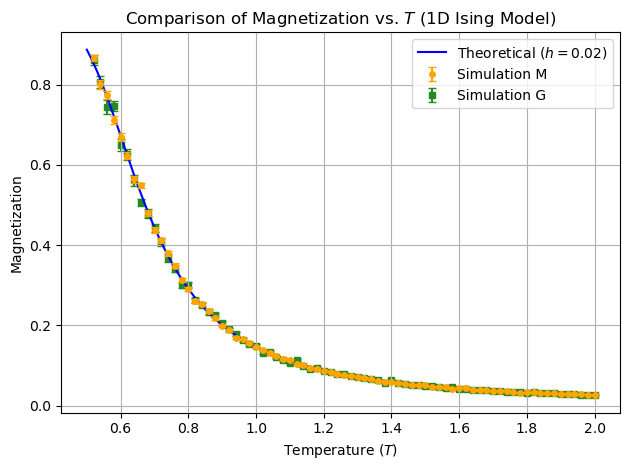

In [54]:
points = 100
T = np.linspace(0.5, 2.0, num=points)
b = 1.0 / T
J = 1.0
Ns = 50
h = 0.02  # External magnetic field

term = np.sqrt(
    np.exp(2 * b * J) * np.cosh(b * h) * np.cosh(b * h) - 2 * np.sinh(2 * b * J)
)
l1 = np.exp(b * J) * np.cosh(b * h) + term
l2 = np.exp(b * J) * np.cosh(b * h) - term
Z = l1**Ns + l2**Ns

M = (
    np.exp(b * J)
    * np.sinh(b * h)
    * (
        (l1 ** (Ns - 1)) * (1 + np.exp(b * J) * np.cosh(b * h) / term)
        + (l2 ** (Ns - 1)) * (1 - np.exp(b * J) * np.cosh(b * h) / term)
    )
) / Z

# Plotting
plt.plot(T, M, label=r"Theoretical ($h=0.02$)", color="blue")

# First simulation
plt.errorbar(
    x_mm,
    mean_mm,
    yerr=err_mm,
    fmt="o",
    ms=4,
    label="Simulation M",
    color="orange",
    capsize=3,
    zorder=2,
)

# Second simulation
plt.errorbar(
    x_gm,
    mean_gm,
    yerr=err_gm,
    fmt="s",
    ms=4,
    label="Simulation G",
    color="forestgreen",
    capsize=3,
    zorder=1,
)

plt.xlabel("Temperature ($T$)")
plt.ylabel(r"Magnetization")
plt.title(r"Comparison of Magnetization vs. $T$ (1D Ising Model)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Gibbs vs. Metropolis: Direct Difference Analysis ($\Delta = \text{Gibbs} - \text{Metropolis}$)

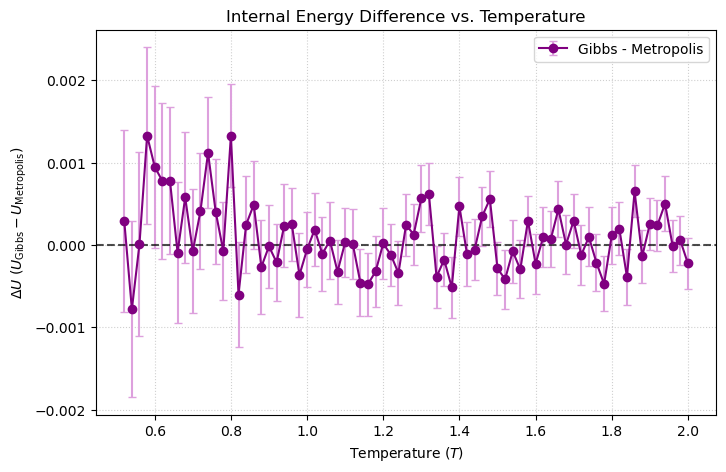

In [73]:

data = np.loadtxt("total_energy.dat")
T = data[:, 0]
mean_m = data[:, 2]
err_m = data[:, 3]


data2 = np.loadtxt("total_energy2.dat")
T2 = data2[:, 0]
mean_g = data2[:, 2]
err_g = data2[:, 3]

# Compute Difference and Error Propagation
diff = mean_g - mean_m
err_diff = np.sqrt(err_g**2 + err_m**2)

# Plotting the Difference
plt.figure(figsize=(8, 5))
plt.errorbar(
    T,
    diff,
    yerr=err_diff,
    fmt="o-",
    color="purple",
    ecolor="plum",
    capsize=3,
    label="Gibbs - Metropolis",
)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.xlabel("Temperature ($T$)")
plt.ylabel(r"$\Delta U$ ($U_{\text{Gibbs}} - U_{\text{Metropolis}}$)")
plt.title("Internal Energy Difference vs. Temperature")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()

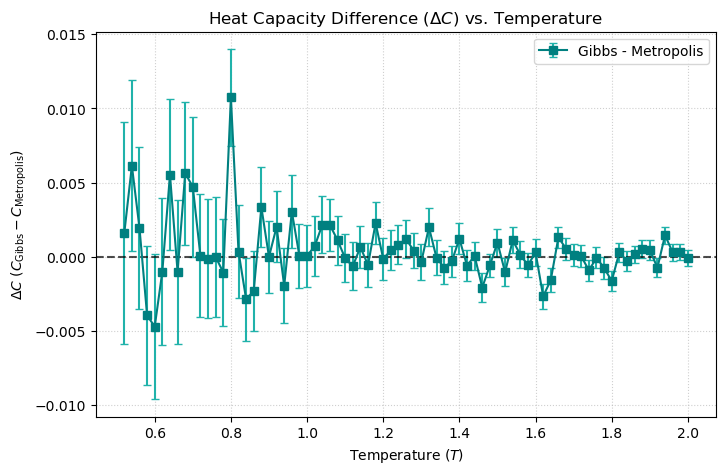

In [84]:
data_c = np.loadtxt("specific_heat.dat")
T_c = data_c[:, 0]
mean_c_m = data_c[:, 1]
err_c_m = data_c[:, 2]


data_c2 = np.loadtxt("specific_heat2.dat")
T_c2 = data_c2[:, 0]
mean_c_g = data_c2[:, 1]
err_c_g = data_c2[:, 2]


diff_c = mean_c_g - mean_c_m
err_diff_c = np.sqrt(err_c_g**2 + err_c_m**2)

plt.figure(figsize=(8, 5))
plt.errorbar(
    T_c,
    diff_c,
    yerr=err_diff_c,
    fmt="s-",
    color="teal",
    ecolor="lightseagreen",
    capsize=3,
    label="Gibbs - Metropolis",
)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"$\Delta C$ ($C_{\text{Gibbs}} - C_{\text{Metropolis}}$)")
plt.title(r"Heat Capacity Difference ($\Delta C$) vs. Temperature")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()

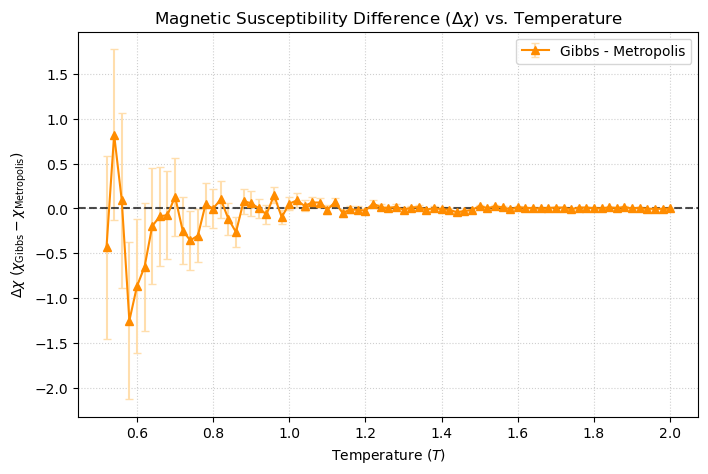

In [80]:
data_chi = np.loadtxt("susceptibility.dat")  
T_chi = data_chi[:, 0]
mean_chi_m = data_chi[:, 2]
err_chi_m = data_chi[:, 3]


data_chi2 = np.loadtxt("susceptibility2.dat")  
T_chi2 = data_chi2[:, 0]
mean_chi_g = data_chi2[:, 2]
err_chi_g = data_chi2[:, 3]

# Compute Difference and Error Propagation
diff_chi = mean_chi_g - mean_chi_m
err_diff_chi = np.sqrt(err_chi_g**2 + err_chi_m**2)

# Plotting the Difference
plt.figure(figsize=(8, 5))
plt.errorbar(
    T_chi,
    diff_chi,
    yerr=err_diff_chi,
    fmt="^-",
    color="darkorange",
    ecolor="navajowhite",
    capsize=3,
    label="Gibbs - Metropolis",
)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(
    r"$\Delta \chi$ ($\chi_{\text{Gibbs}} - \chi_{\text{Metropolis}}$)"
)
plt.title(r"Magnetic Susceptibility Difference ($\Delta \chi$) vs. Temperature")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()

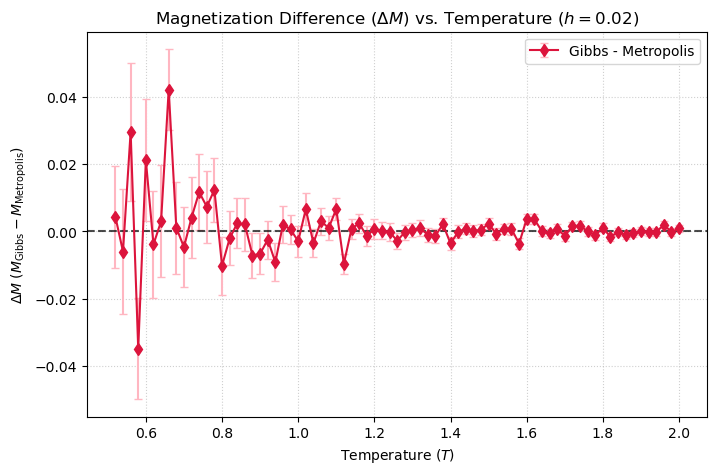

In [82]:
data_m = np.loadtxt("magnetization.dat")  
T_m = data_m[:, 0]
mean_m_m = data_m[:, 2]
err_m_m = data_m[:, 3]


data_m2 = np.loadtxt("magnetization2.dat")  
T_m2 = data_m2[:, 0]
mean_m_g = data_m2[:, 2]
err_m_g = data_m2[:, 3]

# Compute Difference and Error Propagation
diff_m = mean_m_g - mean_m_m
err_diff_m = np.sqrt(err_m_g**2 + err_m_m**2)

# Plotting the Difference
plt.figure(figsize=(8, 5))
plt.errorbar(
    T_m,
    diff_m,
    yerr=err_diff_m,
    fmt="d-",
    color="crimson",
    ecolor="lightpink",
    capsize=3,
    label="Gibbs - Metropolis",
)
plt.axhline(0, color="black", linestyle="--", alpha=0.7)

plt.xlabel(r"Temperature ($T$)")
plt.ylabel(r"$\Delta M$ ($M_{\text{Gibbs}} - M_{\text{Metropolis}}$)")
plt.title(
    r"Magnetization Difference ($\Delta M$) vs. Temperature ($h=0.02$)"
)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.show()